# 06 · Tunnel cost: what would a ~510 m pedestrian/cycle tunnel cost?

Three independent estimates, all in **2025 prices**:

- **A. Top-down.** TfL's November 2017 options report costed an _immersed tunnel_
  on this exact crossing. We take that figure and inflate it.
- **B. Bottom-up.** HS2's _Guide to Tunnelling Costs_ (2011 unit rates): TBM, site
  set-up, bored metres, time-related costs, shafts with lifts, and M&E.
- **C. Benchmark.** The IPA/BTS _Benchmarking tunnelling costs in the UK_ short-tunnel
  rate per km per m² of face area, plus shafts from B.

B and C then get HM Treasury Green Book optimism bias. A is already a
client estimate at option stage, so it gets none.

**Inflation** uses the ONS GDP deflator (YBGB). Construction costs have risen faster
than general prices since 2021, so this probably _understates_ 2025 costs.

**Not included:** land, utilities diversions, Jubilee line protection works
beyond what's in the unit rates, financing, VAT, and running costs. The Greenwich
and Woolwich lifts show that operating and maintaining lifts is a real,
recurring cost.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.geometry import Point

from common import DERIVED, FIGURES, NORTH_PORTAL, RAW, SOUTH_PORTAL, TUNNEL_DETOUR, to_bng

defl = pd.read_csv(RAW / "gdp_deflator.csv", skiprows=8, header=None, names=["period", "index"])
defl = defl[defl.period.str.fullmatch(r"\d{4}")].astype({"period": int, "index": float}).set_index("period")["index"]


def to_2025(gbp: float, year: int) -> float:
    return gbp * defl[2025] / defl[year]


TUNNEL_M = Point(to_bng(SOUTH_PORTAL)).distance(Point(to_bng(NORTH_PORTAL))) * TUNNEL_DETOUR
print(f"Tunnel length: {TUNNEL_M:.0f} m")
print("GDP deflator uplift to 2025:", {y: f"×{defl[2025] / defl[y]:.2f}" for y in (2011, 2016, 2017, 2021)})

Tunnel length: 506 m
GDP deflator uplift to 2025: {2011: '×1.46', 2016: '×1.36', 2017: '×1.33', 2021: '×1.21'}


## Reference class

Sourced comparables (figures as reported; see the source column). Several are **not like-for-like**:

- Silvertown is a PFI finance figure for a twin-bore road tunnel.
- Tideway and Lee are sewers, and the Power Tunnels are small-bore cable tunnels.
- The European figures are renovations of existing tunnels.


In [ ]:
comparables = pd.DataFrame(
    [
        (
            "Rotherhithe–CW immersed tunnel (TfL 2017 option)",
            "this crossing, option estimate",
            330,
            "GBP m",
            2017,
            None,
            None,
            "https://beckettrankine.com/rotherhithe-ferry/ (secondary)",
        ),
        (
            "Rotherhithe–CW opening bridge (TfL 2019)",
            "this crossing, mid-point estimate",
            463,
            "GBP m",
            2019,
            None,
            None,
            "https://en.wikipedia.org/wiki/Rotherhithe_crossing",
        ),
        (
            "Rotherhithe–CW bridge (Sustrans 2015)",
            "this crossing, feasibility study",
            88,
            "GBP m",
            2015,
            None,
            None,
            "https://www.architectsjournal.co.uk/news/study-makes-case-for-88m-east-london-crossing",
        ),
        (
            "Silvertown Tunnel",
            "PFI finance secured, twin-bore road",
            2200,
            "GBP m",
            2021,
            1400,
            10.7,
            "https://en.wikipedia.org/wiki/Silvertown_Tunnel",
        ),
        (
            "Lee Tunnel",
            "whole project incl. deep shafts",
            635,
            "GBP m",
            2013,
            6900,
            7.2,
            "https://en.wikipedia.org/wiki/Lee_Tunnel",
        ),
        (
            "London Power Tunnels ph2",
            "tunnels, 8 shafts, 1 substation",
            1000,
            "GBP m",
            2023,
            32500,
            3.0,
            "https://www.nationalgrid.com/national-grids-london-power-tunnels-breakthrough-completes-ps1-billion-projects-tunnelling-activity",
        ),
        (
            "Tyne Pedestrian & Cyclist Tunnels",
            "refurbishment + new lifts (outturn)",
            16,
            "GBP m",
            2019,
            270,
            3.7,
            "https://www.walkwheelcycletrust.org.uk/our-blog/news/tyne-pedestrian-and-cyclist-tunnels-reopen-after-six-years/",
        ),
        (
            "Greenwich & Woolwich foot tunnels",
            "5-yr refurbishment incl. 4 lifts",
            11.5,
            "GBP m",
            2012,
            370,
            2.7,
            "https://thomascallum.com/projects/greenwich-foot-tunnels/",
        ),
        (
            "Hamburg Old Elbe Tunnel",
            "renovation of 2 tubes",
            131,
            "EUR m",
            2023,
            426,
            6.0,
            "https://en.wikipedia.org/wiki/Elbe_Tunnel_(1911)",
        ),
        (
            "Antwerp St Anna tunnel",
            "lift renovation + 2 yrs maintenance",
            4.9,
            "EUR m",
            2022,
            572,
            4.3,
            "https://www.lydiapeeters.be/nieuws/volledige-renovatie-liften-sint-annatunnel-start-vanaf-januari-2022/",
        ),
        (
            "Lyon Croix-Rousse modes doux",
            "new bus/ped/cycle tube + safety works",
            282.8,
            "EUR m",
            2013,
            1800,
            10.0,
            "https://road.cc/content/news/112664-video-lyons-stunning-new-cyclist-pedestrian-tunnel-feature-dauphin%C3%A9-time-trial",
        ),
    ],
    columns=["project", "covers", "cost", "unit", "price_year", "length_m", "diameter_m", "source"],
)

EUR_GBP = 0.86  # approximate; for context only
comparables["cost_gbp_m_2025"] = [
    to_2025(c * (EUR_GBP if u == "EUR m" else 1), y)
    for c, u, y in zip(comparables.cost, comparables.unit, comparables.price_year)
]
comparables.drop(columns="source").round(1)

,project,covers,cost,unit,price_year,length_m,diameter_m,cost_gbp_m_2025
0,Rotherhithe–CW immersed tunnel (TfL 2017 option),"this crossing, option estimate",330.0,GBP m,2017,NaN,NaN,440.4
1,Rotherhithe–CW opening bridge (TfL 2019),"this crossing, mid-point estimate",463.0,GBP m,2019,NaN,NaN,591.5
2,Rotherhithe–CW bridge (Sustrans 2015),"this crossing, feasibility study",88.0,GBP m,2015,NaN,NaN,121.4
3,Silvertown Tunnel,"PFI finance secured, twin-bore road",2200.0,GBP m,2021,1400.0,10.7,2662.2
4,Lee Tunnel,whole project incl. deep shafts,635.0,GBP m,2013,6900.0,7.2,896.3
5,London Power Tunnels ph2,"tunnels, 8 shafts, 1 substation",1000.0,GBP m,2023,32500.0,3.0,1077.0
6,Tyne Pedestrian & Cyclist Tunnels,refurbishment + new lifts (outturn),16.0,GBP m,2019,270.0,3.7,20.4
7,Greenwich & Woolwich foot tunnels,5-yr refurbishment incl. 4 lifts,11.5,GBP m,2012,370.0,2.7,16.6
8,Hamburg Old Elbe Tunnel,renovation of 2 tubes,131.0,EUR m,2023,426.0,6.0,121.3
9,Antwerp St Anna tunnel,lift renovation + 2 yrs maintenance,4.9,EUR m,2022,572.0,4.3,4.8


## A · Top-down: TfL's 2017 immersed-tunnel estimate


In [3]:
A = {"low": to_2025(325, 2017), "central": to_2025(330, 2017), "high": to_2025(335, 2017)}
print({k: f"£{v:.0f}m" for k, v in A.items()})

{'low': '£434m', 'central': '£440m', 'high': '£447m'}


## B · Bottom-up from HS2 unit rates (2Q2011)

HS2's twin-bore rate is £22–25k per _route_ metre, so we halve it for a single bore
and scale by face area. HS2 bores are ~8.8 m outside diameter (OD). We assume
~7 m OD, enough for a ~6 m internal diameter with a cycle track and footway.
Shafts: HS2 puts a ventilation shaft with lift and head house at £10–30m. Ours
need large bike-capable lifts, redundancy and a public entrance building, so
the central case sits at the upper end.


In [ ]:
OD_M, HS2_OD_M = 7.0, 8.8
face_scale = (OD_M / HS2_OD_M) ** 2

unit = pd.DataFrame(
    {
        "item": [
            "TBM (purchase/refurb)",
            "fixed site set-up (both portals)",
            "bored tunnel",
            "time-related (weeks on site)",
            "shafts + lifts + entrance buildings (×2)",
            "M&E fit-out",
        ],
        "low": [16, 35, 22e3 / 2 * face_scale * TUNNEL_M / 1e6, 1.1 * 52, 2 * 15, 4e3 * TUNNEL_M / 1e6],
        "central": [17, 40, 23.5e3 / 2 * face_scale * TUNNEL_M / 1e6, 1.1 * 78, 2 * 25, 4e3 * TUNNEL_M / 1e6],
        "high": [18, 45, 25e3 / 2 * face_scale * TUNNEL_M / 1e6, 1.1 * 104, 2 * 30, 6e3 * TUNNEL_M / 1e6],
    }
).set_index("item")
unit_2025 = unit.apply(lambda col: col.map(lambda v: to_2025(v, 2011)))
unit_2025.loc["base cost (2025 £m)"] = unit_2025.sum()
unit_2025.round(1)

,low,central,high
item,,,
TBM (purchase/refurb),23.4,24.9,26.3
fixed site set-up (both portals),51.2,58.5,65.8
bored tunnel,5.2,5.5,5.9
time-related (weeks on site),83.7,125.6,167.4
shafts + lifts + entrance buildings (×2),43.9,73.2,87.8
M&E fit-out,3.0,3.0,4.4
base cost (2025 £m),210.3,290.6,357.7


## C · IPA/BTS short-tunnel benchmark (2016/17)

One ~0.65 km UK transport tunnel came out at **£5.63m per km per m² of face area**.
That covers the tunnel only, so we add the shafts from B.


In [ ]:
face_m2 = np.pi * (OD_M / 2) ** 2
ipa_tunnel = to_2025(5.63 * face_m2 * TUNNEL_M / 1000, 2016)
C_base = {
    k: ipa_tunnel + unit_2025.loc["shafts + lifts + entrance buildings (×2)", k] for k in ("low", "central", "high")
}
print(
    f"Face area {face_m2:.1f} m² → tunnel £{ipa_tunnel:.0f}m; with shafts:",
    {k: f"£{v:.0f}m" for k, v in C_base.items()},
)

Face area 38.5 m² → tunnel £149m; with shafts: {'low': '£193m', 'central': '£222m', 'high': '£237m'}


## Optimism bias and summary

Green Book supplementary guidance gives upper-bound optimism bias of **44% for standard
civil engineering** and **66% for non-standard civil engineering** at the outline
business case stage. A deep river crossing with lifts is closer to non-standard.


In [ ]:
OB = {"low": 0.44, "central": 0.55, "high": 0.66}
B = {k: unit_2025.loc["base cost (2025 £m)", k] * (1 + OB[k]) for k in OB}
C = {k: C_base[k] * (1 + OB[k]) for k in OB}
cost = pd.DataFrame(
    {
        "A: TfL 2017 immersed (inflated)": A,
        "B: HS2 unit rates + optimism bias": B,
        "C: IPA benchmark + shafts + optimism bias": C,
    }
).T
cost.round(0)

,low,central,high
A: TfL 2017 immersed (inflated),434.0,440.0,447.0
B: HS2 unit rates + optimism bias,303.0,450.0,594.0
C: IPA benchmark + shafts + optimism bias,277.0,344.0,393.0


In [7]:
COST_RANGE = {"low": cost["low"].min(), "central": cost["central"].median(), "high": cost["high"].max()}
print("Working cost range (2025 £m):", {k: round(v) for k, v in COST_RANGE.items()})
pd.Series(COST_RANGE).to_csv(DERIVED / "cost_range.csv", header=["gbp_m_2025"])

Working cost range (2025 £m): {'low': 277, 'central': 440, 'high': 594}


## Can land readjustment pay for it?

Both sides are in **present value**. Reserve-land receipts come from notebook 05
(750 m area, central tunnel premium, phased build-out). Tunnel spend is spread evenly over
`CONSTRUCTION_YEARS` and discounted at the same rates.


In [ ]:
CONSTRUCTION_YEARS = [2, 3, 4, 5]  # after ~2 years of design and consents
DISCOUNT_RATES = {"3.5% (Green Book)": 0.035, "7% (commercial)": 0.07}
pv_cost = {
    label: {k: v * np.mean([(1 + r) ** -t for t in CONSTRUCTION_YEARS]) for k, v in COST_RANGE.items()}
    for label, r in DISCOUNT_RATES.items()
}
pd.DataFrame(pv_cost).T.round(0).rename(columns=lambda c: f"PV cost {c} (£m)")

,PV cost low (£m),PV cost central (£m),PV cost high (£m)
3.5% (Green Book),246.0,391.0,527.0
7% (commercial),220.0,349.0,470.0


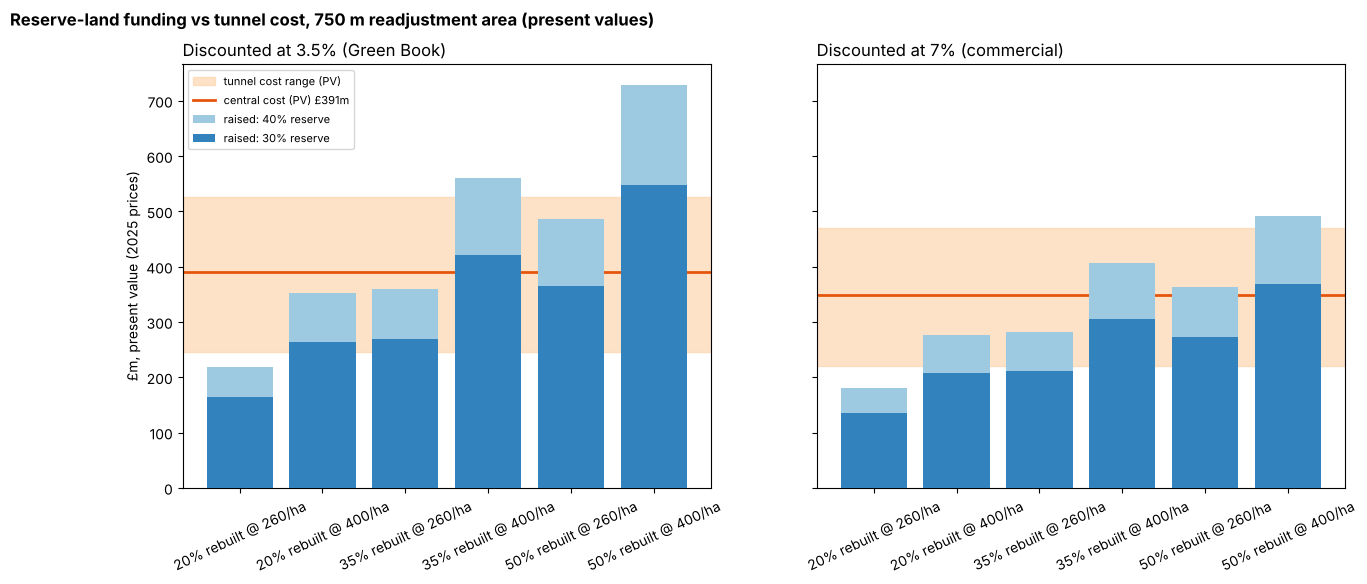

In [ ]:
scen = pd.read_csv(DERIVED / "development_scenarios_750m.csv")
scen = scen[scen["tunnel premium case"] == "Central"]
scen["label"] = scen["redeveloped share"] + " rebuilt @ " + scen["target homes/ha"].astype(str) + "/ha"

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, label in zip(axes, DISCOUNT_RATES):
    col = f"PV reserve funding @ {label} (£m)"
    wide = scen.pivot_table(index="label", columns="reserve share", values=col, sort=False)
    c = pv_cost[label]
    ax.axhspan(c["low"], c["high"], color="#fdd0a2", alpha=0.6, label="tunnel cost range (PV)")
    ax.axhline(c["central"], color="#e6550d", lw=2, label=f"central cost (PV) £{c['central']:.0f}m")
    x = np.arange(len(wide))
    ax.bar(x, wide["40%"], color="#9ecae1", label="raised: 40% reserve", zorder=3)
    ax.bar(x, wide["30%"], color="#3182bd", label="raised: 30% reserve", zorder=3)
    ax.set_xticks(x, wide.index, rotation=25)
    ax.set_title(f"Discounted at {label}", loc="left")
axes[0].set_ylabel("£m, present value (2025 prices)")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle(
    "Reserve-land funding vs tunnel cost, 750 m readjustment area (present values)",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.savefig(FIGURES / "06_funding_vs_cost.png", dpi=150, bbox_inches="tight")

In [ ]:
out = {}
for label in DISCOUNT_RATES:
    wide = scen.pivot_table(
        index="label", columns="reserve share", values=f"PV reserve funding @ {label} (£m)", sort=False
    )
    for rs in wide.columns:
        out[(label, f"{rs} reserve")] = (wide[rs] / pv_cost[label]["central"]).map("{:.0%}".format)
pd.DataFrame(out)  # PV funding as % of PV central cost

3.5% (Green Book)             7% (commercial)            
                           30% reserve 40% reserve     30% reserve 40% reserve
label                                                                         
20% rebuilt @ 260/ha               42%         56%             39%         52%
20% rebuilt @ 400/ha               68%         90%             60%         80%
35% rebuilt @ 260/ha               69%         92%             61%         81%
35% rebuilt @ 400/ha              108%        143%             87%        117%
50% rebuilt @ 260/ha               93%        124%             78%        104%
50% rebuilt @ 400/ha              140%        187%            106%        141%